# A simple non-Poissonian example

In [1]:
%load_ext autoreload
%autoreload 2

import sys, os
sys.path.append("/group/hepheno/smsharma/NPTFit/Full_Testing")

import copy
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp

import bayesian_scan_models as bsm #module for performing scan
# import analysis_classes.fermi_analysis as fa  #module for analysing scan

%matplotlib inline

## Define the directories and physics variables for the scan

In [2]:
work_dir = '/group/hepheno/smsharma/NPTFit/Full_Testing/'
psf_dir = work_dir + '/psf_dir/'

In [3]:
tag = 'Example'
run_tag = 'NPTF_test_en_8_16' 

In [4]:
# CTB min max used for plotting 3FGL
CTB_en_min = 8
CTB_en_max=16
nside=128

In [5]:
mask_type = '0.95' 
force_energy = True 
energy_bin_mask = 8 

## Now we will make an instance of bayesian_scan_models to setup the template scan

### Setting up the scan

In [6]:
iso_temp = [hp.ud_grade(np.load("../../Fermi_Data/Template_iso.npy"),nside,power=-2)]

In [7]:
fermi_data = hp.ud_grade(np.load("../../Fermi_Data/FermiData_counts.npy"),nside,power=-2)
fermi_exposure = hp.ud_grade(np.load("../../Fermi_Data/FermiData_exposure.npy"),nside,power=-2)
fermi_psc_mask = hp.ud_grade(np.load("../../Fermi_Data/FermiData_pscmask.npy"),nside,power=-2)

In [8]:
b = bsm.bayesian_scan_NPTF(tag=tag,nside=nside,work_dir=work_dir,psf_dir=psf_dir)
b.load_data(fermi_data, fermi_exposure)
import create_mask as cm
analysis_mask = cm.make_mask_total(nside, mask_ring = True, outer = 2, ring_b = 90-150)
b.load_mask(analysis_mask)
#temp_dict = {'iso': iso_temp}
b.add_template(iso_temp,'iso')


Now let's add our Poissonian models

In [9]:
b.add_poiss_model('iso','$A_{iso}$',[-2,2],False)

In [10]:
b.add_non_poiss_model('iso',['$\\tilde A_{ps}$','$n_1$','$n_2$','$S_b^{(1)}$'],[[-6,6],[2.05,30],[-2,1.95],[0.05,30]],[True,False,False,False])

Now, we will initiate the NPTF.  We have 2 PS templates, so we use `b.initiate_2_ps_edep`.  There are also functions for initializing 1 PS and 3 PS.

In [11]:
f_ary, df_ary = np.load("../../Full_Testing/psf_dir/gauss_128_0.181.npy")

In [12]:
b.initiate_ps_from_f_ary(f_ary, df_ary)

/group/hepheno/smsharma/NPTFit/Full_Testing/config_file.py:221: VisibleDeprecationWarning: using a non-integer number instead of an integer will result in an error in the future
  new_data_masked[mask_array[i]] = 1


$A_{iso}$
0 [True, False, False, False]
1 [True, False, False, False]
2 [True, False, False, False]
3 [True, False, False, False]
The k_max_array is  [16.0]
The number of parameters is  5


### Running the scan

In [13]:
np.array_split([0.0025792849368498085, 25.259443157900002, 1.45042572618, 24.857922928711869],1)

[array([  2.57928494e-03,   2.52594432e+01,   1.45042573e+00,
          2.48579229e+01])]

In [14]:
hp.version

<module 'healpy.version' from '/group/hepheno/venv_astropy/lib/python2.7/site-packages/healpy/version.pyc'>

In [15]:
b.perform_scan(run_tag=run_tag)

/group/hepheno/smsharma/NPTFit/Full_Testing/chains/Example/NPTF_test_en_8_16/


## Analysis

In [16]:
sys.path.append("/group/hepheno/heptools/Fermi-NPTF-exposure/")
import analysis_classes.fermi_analysis as fa  #module for analysing scan

In [17]:
outer_plot=10 #this is the outer radius for the spectrum analysis
kwargs_spectrum={'mask_ring': True, 'outer': 2, 'lat': 150}

In [19]:
import baseline_analysis as fa

In [21]:
cs=fa.compute_edep_spectra(b,run_tag,[8,16],**kwargs_spectrum)

In load_scan: polychord, minuit: False False
  analysing data from /group/hepheno/smsharma/NPTFit/Full_Testing/chains/Example/NPTF_test_en_8_16/.txt
the medians are  [1.1784537722329496, -1.5622942828159652, 15.332161440109122, -0.5552539762462589, 24.648659156925117]
the medians (from chains) are  [  1.17784484  -1.56259327  15.68904271  -0.57278638  24.37314418]
the number of parameters is  5
Len of fixed params list:  0
self.poiss_comp_numbers:  {'iso-0': 0}


In [22]:
print 'iso PS: ', cs.return_intensity_arrays_non_poiss('iso',0)

iso PS:  [  3.13464980e-09   5.45480584e-09   8.07318885e-09]


In [23]:
print 'iso: ',cs.cs_array[0].return_poiss_intensity_conf_int('iso-0',quant = [0.16,0.5,0.84])

iso:  at comp  iso-0 log prior:  False intensity:  [  1.49287095e-08   1.67509335e-08   1.87550313e-08]
[  1.49287095e-08   1.67509335e-08   1.87550313e-08]


In [24]:
b.calculate_medians()

the medians are  [1.1784537722329496, -1.5622942828159652, 15.332161440109122, -0.5552539762462589, 24.648659156925117]
the medians (from chains) are  [  1.17784484  -1.56259327  15.68904271  -0.57278638  24.37314418]
the number of parameters is  5


In [27]:
b.total_exposure_map = b.exposure_map

In [28]:
pdnds = fa.plot_dnds(b,**kwargs_spectrum)

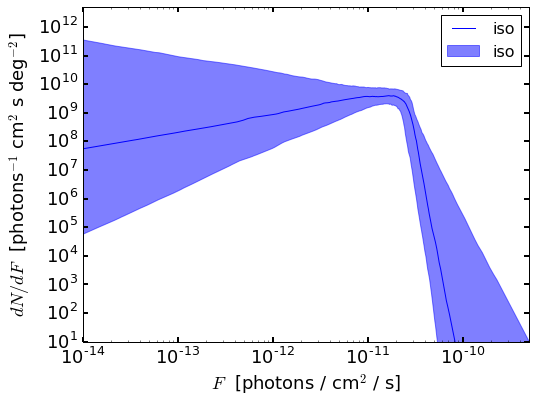

In [29]:
plt.figure(figsize=(8,6))
#plot medians
pdnds.plot_source_count_median('iso',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,color='blue',label='iso')

#plot band
pdnds.plot_source_count_band('iso',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,qs=[0.16,0.5,0.84],color='blue',label='iso',alpha=0.5)

plt.legend(fontsize=16) 

plt.yscale('log')
plt.xscale('log')
plt.xlim([1e-14,5e-10])
plt.ylim([1e1,5e12])

plt.tick_params(axis='x', length=5,width=2,labelsize=18)
plt.tick_params(axis='y',length=5,width=2,labelsize=18)
plt.xlabel('$F$  [photons / cm$^2$ / s]', fontsize=18)
plt.ylabel('$dN/dF$  [photons$^{-1}$ cm$^2$ s deg$^{-2}$]', fontsize=18)

plt.show()